# Part 2: Word Embeddings and Semantic Drift

This notebook **explores saved results** from CS533 Homework 1, Part 2. It does not train models or recompute the large Google News analysis.

- **P1:** New York Times articles from 2005 to 2014.
- **P2:** Articles from 2015 to 2025 (partial 2025 coverage).
- **M1:** Trained on P1. **M2:** Continued from M1 on P2. **M3:** Trained from scratch on P2.
- **GN:** Pretrained Google News word vectors, analyzed on Bilkent Leylak.

Run the cells **from top to bottom**. Paths below match the project on the Surface Pro.

In [48]:
# 1. Imports and saved-result paths
from pathlib import Path
import json
import html

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from gensim.models import Word2Vec
from sklearn.decomposition import PCA
from IPython.display import HTML, display

DATA = Path(r"C:\Projects\IR\data")
MODELS = DATA / "models"
RESULTS = DATA / "part2_results"
PLOTS = RESULTS / "plots"

model_files = {
    "M1": MODELS / "w2v_P1.model",
    "M2": MODELS / "w2v_P2_continued.model",
    "M3": MODELS / "w2v_P2_fresh.model",
}

for label, file in model_files.items():
    assert file.exists(), f"Missing {label}: {file}"
print("All three model files found.")

All three model files found.


## 2.1 to 2.4: Exploring the trained models

The models were trained in `src/`, **not inside this notebook**. Here we load them and check vocabulary sizes and sample word associations. M2 starts with M1's vectors, while M3 is independently trained on P2.

In [49]:
# 2. Load the saved Word2Vec models once
m1 = Word2Vec.load(str(model_files["M1"]))
m2 = Word2Vec.load(str(model_files["M2"]))
m3 = Word2Vec.load(str(model_files["M3"]))

model_summary = pd.DataFrame([
    {"Model": "M1", "Training": "P1, from scratch", "Vocabulary": len(m1.wv)},
    {"Model": "M2", "Training": "M1 continued on P2", "Vocabulary": len(m2.wv)},
    {"Model": "M3", "Training": "P2, from scratch", "Vocabulary": len(m3.wv)},
])
display(model_summary)
print("Words added to M2:", len(set(m2.wv.key_to_index) - set(m1.wv.key_to_index)))

,Model,Training,Vocabulary
0,M1,"P1, from scratch",66853
1,M2,M1 continued on P2,71819
2,M3,"P2, from scratch",51346


Words added to M2: 4966


In [50]:
# 3. Sanity check: eight M1 neighbors for five familiar words
sanity_words = ["government", "economy", "baseball", "music", "technology"]
rows = []
for word in sanity_words:
    neighbors = [w for w, _ in m1.wv.most_similar(word, topn=8)]
    rows.append({"Word": word, "M1 nearest neighbors": ", ".join(neighbors)})

display(pd.DataFrame(rows))

,Word,M1 nearest neighbors
0,government,"goverment, governments, clampdown, yingluck, r..."
1,economy,"recession, economic, weakening, economies, inf..."
2,baseball,"league, selig, chass, leagues, sluggers, yanke..."
3,music,"edm, classical, electronica, rdio, songs, jazz..."
4,technology,"technologies, coders, tech, virtualization, me..."


## 2.5: Measuring semantic drift

**Semantic drift** means that a word's typical context or associations change between periods.

We saved three measurements for **44 words**:

1. `cos_cont`: Cosine similarity between M1 and continued M2. Lower values indicate greater change.
2. `cos_align`: Cosine similarity between M1 and fresh M3 after aligning M3 to M1. Lower values indicate greater change.
3. `nn_at_10`: Fraction of the ten nearest neighbors shared by M1 and M3. `0.0` means no shared neighbors; `1.0` means all ten are shared.

The alignment uses 20,000 common words to map M3 vectors into M1's coordinate system. **Raw M1 and M3 vectors cannot be directly compared** because the models were trained separately.

In [51]:
# 4. Show all 44 words ranked by aligned semantic drift
drift_df = pd.read_csv(RESULTS / "semantic_drift.csv")
ranked = drift_df.sort_values("drift_rank")

cols = ["drift_rank", "word", "group", "cos_cont", "cos_align", "nn_at_10"]
display(ranked[cols].round(3).reset_index(drop=True))

print("Words analyzed:", len(ranked))
print("Five most drifted:", ranked["word"].head(5).tolist())
print("Five most stable:", ranked["word"].tail(5).tolist())

,drift_rank,word,group,cos_cont,cos_align,nn_at_10
0,1,pence,drift_candidate,0.318,0.190,0.0
1,2,trump,drift_candidate,0.285,0.222,0.1
2,3,distancing,drift_candidate,0.263,0.237,0.0
3,4,zoom,drift_candidate,0.284,0.259,0.0
4,5,ai,drift_candidate,0.273,0.272,0.0
5,6,meta,drift_candidate,0.317,0.281,0.0
6,7,booster,drift_candidate,0.412,0.312,0.1
7,8,variant,drift_candidate,0.373,0.328,0.0
8,9,lockdown,drift_candidate,0.378,0.365,0.2
9,10,mask,drift_candidate,0.409,0.381,0.1


Words analyzed: 44
Five most drifted: ['pence', 'trump', 'distancing', 'zoom', 'ai']
Five most stable: ['wine', 'mountain', 'privacy', 'baseball', 'election']


In [52]:
# 5. Compare the drift measures, and show why alignment matters
scores = drift_df[["cos_cont", "cos_align", "nn_at_10"]]
print("Spearman rank correlations:")
display(scores.corr(method="spearman").round(4))

print("Raw M1/M3 cosine versus aligned M1/M3 cosine:")
examples = drift_df[drift_df["word"].isin(["privacy", "internet", "phone"])]
display(examples[["word", "raw_cos_m1_m3", "cos_align"]].round(4))

Spearman rank correlations:


,cos_cont,cos_align,nn_at_10
cos_cont,1.0000,0.9204,0.7125
cos_align,0.9204,1.0000,0.7333
nn_at_10,0.7125,0.7333,1.0000


Raw M1/M3 cosine versus aligned M1/M3 cosine:


,word,raw_cos_m1_m3,cos_align
33,internet,0.0899,0.6658
34,phone,0.0548,0.6747
41,privacy,-0.0207,0.7536


In [53]:
# 6. All ten required M1/M2 neighborhood comparisons
most_drifted = ["pence", "trump", "distancing", "zoom", "ai"]
most_stable = ["election", "baseball", "privacy", "mountain", "wine"]

rows = []
for word in most_drifted + most_stable:
    old = [w for w, _ in m1.wv.most_similar(word, topn=8)]
    new = [w for w, _ in m2.wv.most_similar(word, topn=8)]
    rows.append({
        "Word": html.escape(word),
        "M1 neighbors (P1)": "<br>".join(map(html.escape, old)),
        "M2 neighbors (continued on P2)": "<br>".join(map(html.escape, new)),
    })

display(HTML(pd.DataFrame(rows).to_html(index=False, escape=False)))

Word,M1 neighbors (P1),M2 neighbors (continued on P2)
pence,billonretek743valuingunitabkronor879551,mikepompeokainevicekamalahuckabeekellyannepawlenty
trump,ivankadonaldivanamelaniaozymandiascasinoextellkepcher,presidentdonaldbidenobamaelecttacopinapresdeclassification
distancing,distancedrepudiatingdisqualifyingextricatedassailingrebukingdisentangleextricate,precautionssocialmaskmasksquarantinesquarantineprotocolsmasking
zoom,easysharepentaxslrmegapixelm8megapixelspowershottelephoto,facetimevirtualvideoconferencingconferencingschoolworksederschatskype
ai,weiweiqiangguocaiartistragnarkjartanssonzhen,artificialgenerativechatgptanthropicchatbotsdeepseekopenaichatbot
election,electionspresidentialmidtermelectoralrunoffprimaryprimariesparliamentary,electionsmidtermpresidentialreelectiondelegitimizerunoffsvoteparliamentary
baseball,leagueseligchassleaguessluggersyankeessolarteleaguers,mlbleaguesolarteleaguespitcherohtaniballplayersleaguers
privacy,googleicloudintrusionscopyrightsnsabrowserssnoopingfacetime,encryptionicloudfacebooksafeguardsimessagecyberbullyingdataliberties
mountain,mountainsbelleayrewasatchslopesbackcountryfoothillscragsski,mountainsslopesberryessamassifsnowmassskiwasatchbelleayre
wine,winespinottastingcabernetvintagesbordeauxsyrahcavas,winesnonalcoholiccidersroséchardonnaychampagnespinotburgundies


## 2.6: Comparing with Google News

We compare how many of GN's ten nearest neighbors also appear among the ten nearest neighbors in M1 or M2. GN's candidates were restricted to words from M1 that could be found in GN.

**A higher overlap means more shared neighbors, not necessarily the same word meaning.** The Google News model is case-sensitive, so capitalization and different word senses can affect the result.

In [54]:
# 7. Load saved GN analysis (no large GN model needed)
with open(RESULTS / "gn_comparison.json", encoding="utf-8") as f:
    gn_results = json.load(f)

gn_df = pd.DataFrame(gn_results["words"])
print("Words compared:", len(gn_df))
print("Mean GN-M1 overlap:", round(gn_df["nn_gn_m1"].mean(), 4))
print("Mean GN-M2 overlap:", round(gn_df["nn_gn_m2"].mean(), 4))
print("\nCloser to GN:")
print(gn_df["closer_to"].value_counts().to_string())

Words compared: 44
Mean GN-M1 overlap: 0.2023
Mean GN-M2 overlap: 0.1818

Closer to GN:
closer_to
tie    21
M1     14
M2      9


In [55]:
# 8. Examples of agreement and disagreement
example_words = ["zoom", "ai", "trump", "apple", "vaccine", "phone", "election"]
examples = gn_df[gn_df["word"].isin(example_words)]
display(examples[["word", "nn_gn_m1", "nn_gn_m2", "closer_to"]].reset_index(drop=True))

print("Words with zero overlap against both models:")
zero_both = gn_df[(gn_df["nn_gn_m1"] == 0) & (gn_df["nn_gn_m2"] == 0)]
print(", ".join(zero_both["word"].tolist()))

,word,nn_gn_m1,nn_gn_m2,closer_to
0,zoom,0.2,0.0,M1
1,trump,0.0,0.0,tie
2,ai,0.0,0.0,tie
3,vaccine,0.1,0.3,M2
4,apple,0.0,0.0,tie
5,phone,0.7,0.6,M1
6,election,0.5,0.5,tie


Words with zero overlap against both models:
delta, trump, meta, ai, tesla, uber, apple, corona, bridge


## 2.7: Visualizing semantic drift with PCA

For each word, we plot **18 vectors together**: the word and eight neighbors from M1, plus the word and eight neighbors from continued M2.

PCA reduces those 300-dimensional vectors to two dimensions so that we can draw them. The arrow shows the target word's change from M1 to M2. Because M2 continues training from M1, we can place them in a joint projection.

**Limitation:** Each plot uses its own PCA projection and shows only part of the original information. The 2D distances and arrow lengths are illustrations, not exact semantic-drift scores. Existing PNG files are not overwritten automatically.

In [56]:
# 9. One reusable function for all four PCA plots
def plot_semantic_drift(word, save_dir=PLOTS):
    old = [w for w, _ in m1.wv.most_similar(word, topn=8)]
    new = [w for w, _ in m2.wv.most_similar(word, topn=8)]

    vectors = np.vstack(
        [m1.wv[word]] + [m1.wv[w] for w in old]
        + [m2.wv[word]] + [m2.wv[w] for w in new]
    )
    assert vectors.shape == (18, 300)

    pca = PCA(n_components=2)
    points = pca.fit_transform(vectors)
    retained = float(pca.explained_variance_ratio_.sum())

    fig, ax = plt.subplots(figsize=(12, 8))
    ax.scatter(points[1:9, 0], points[1:9, 1], color="royalblue",
               marker="o", label="M1 neighbors")
    ax.scatter(points[10:18, 0], points[10:18, 1], color="darkorange",
               marker="s", label="M2 neighbors")
    ax.scatter(*points[0], color="navy", marker="*", s=270, label=f"M1: {word}")
    ax.scatter(*points[9], color="darkred", marker="*", s=270, label=f"M2: {word}")

    for indices, names in [(range(1, 9), old), (range(10, 18), new)]:
        for i, name in zip(indices, names):
            y_offset = 5 if i % 2 == 0 else -11
            ax.annotate(name, points[i], xytext=(5, y_offset),
                        textcoords="offset points", fontsize=8)
    ax.annotate(f"{word} (M1)", points[0], xytext=(6, 6),
                textcoords="offset points", fontsize=9, weight="bold")
    ax.annotate(f"{word} (M2)", points[9], xytext=(6, 6),
                textcoords="offset points", fontsize=9, weight="bold")
    ax.annotate("", xy=points[9], xytext=points[0],
                arrowprops=dict(arrowstyle="->", color="black", lw=2))

    ax.set(title=f"Semantic Drift: {word} (PCA variance: {retained:.1%})",
           xlabel="PCA Component 1", ylabel="PCA Component 2")
    ax.grid(alpha=0.25)
    ax.legend()
    fig.tight_layout()

    save_dir.mkdir(parents=True, exist_ok=True)
    output = save_dir / f"{word}_drift_plot.png"
    if output.exists():
        print("Existing PNG kept:", output)
    else:
        fig.savefig(output, dpi=250, bbox_inches="tight")
        print("Saved new PNG:", output)
    plt.show()
    plt.close(fig)
    print(f"{word}: 18 vectors; PCA variance retained = {retained:.1%}")

Existing PNG kept: C:\Projects\IR\data\part2_results\plots\zoom_drift_plot.png


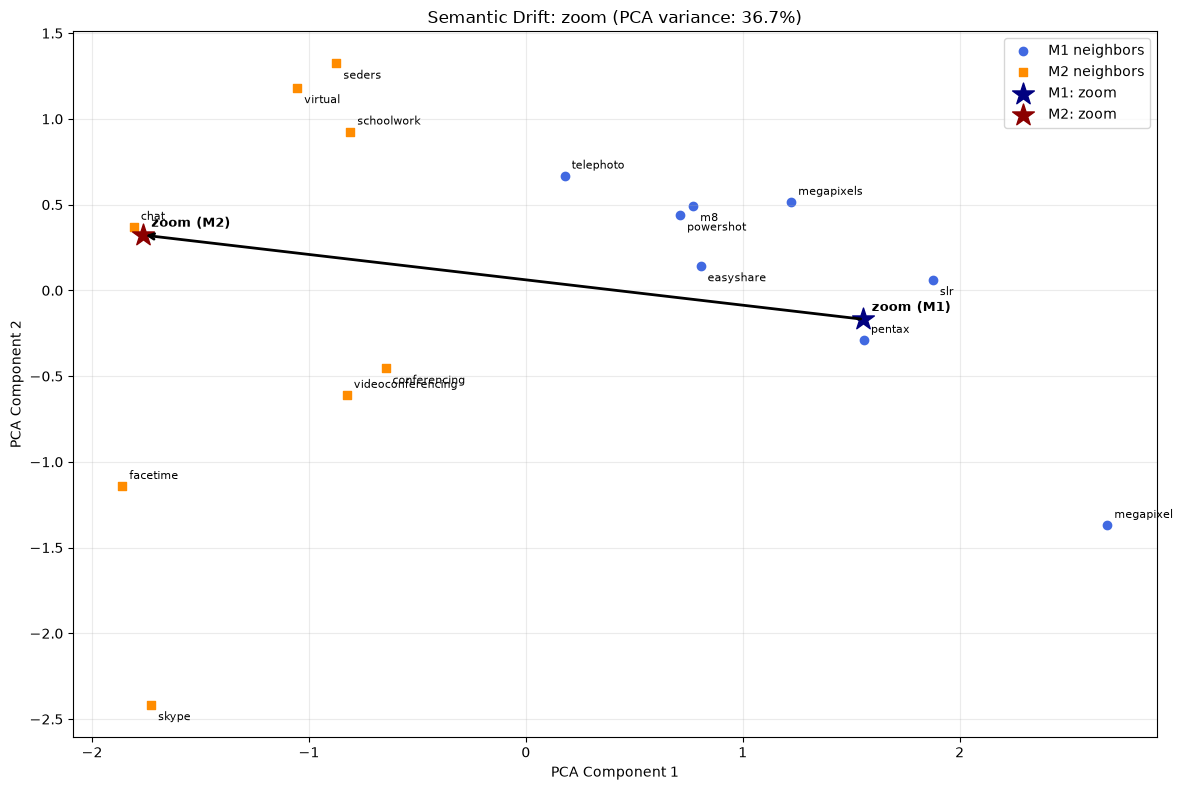

zoom: 18 vectors; PCA variance retained = 36.7%


In [57]:
# 10. Zoom: cameras to video calls
plot_semantic_drift("zoom")

Existing PNG kept: C:\Projects\IR\data\part2_results\plots\ai_drift_plot.png


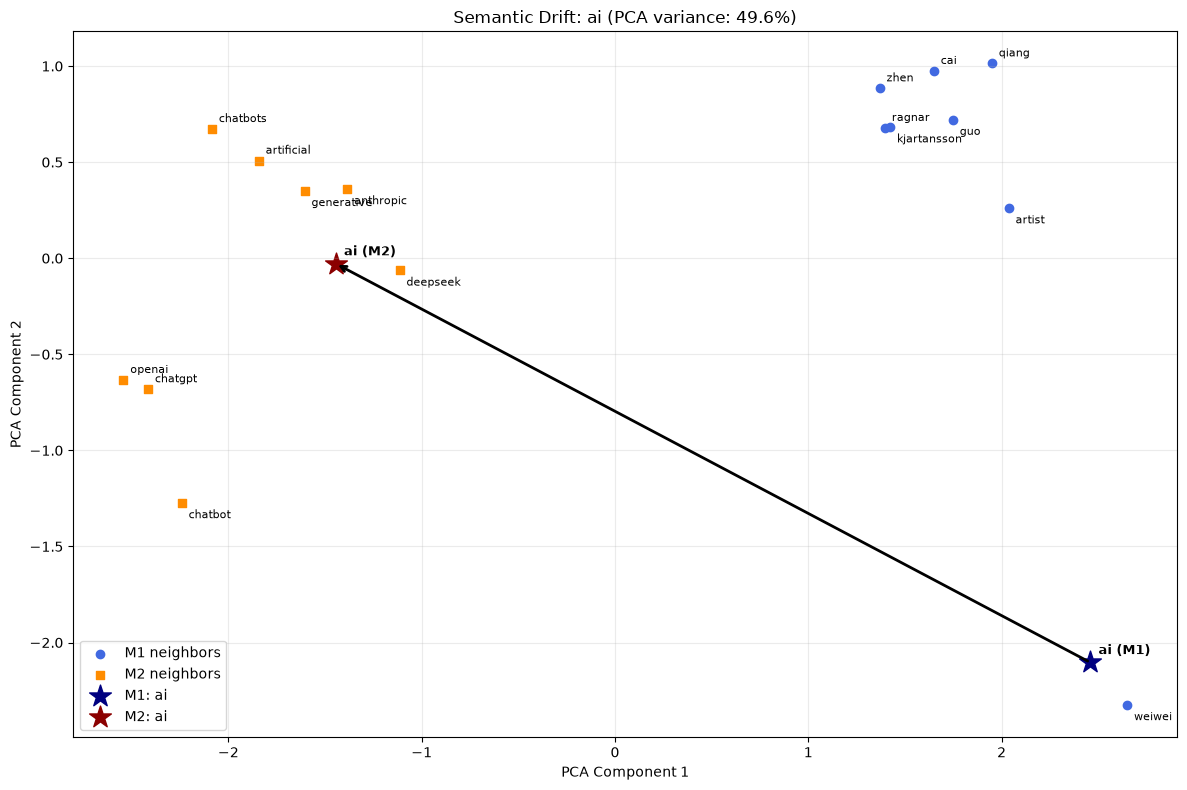

ai: 18 vectors; PCA variance retained = 49.6%


In [58]:
# 11. AI: names/art to artificial intelligence
plot_semantic_drift("ai")

Existing PNG kept: C:\Projects\IR\data\part2_results\plots\trump_drift_plot.png


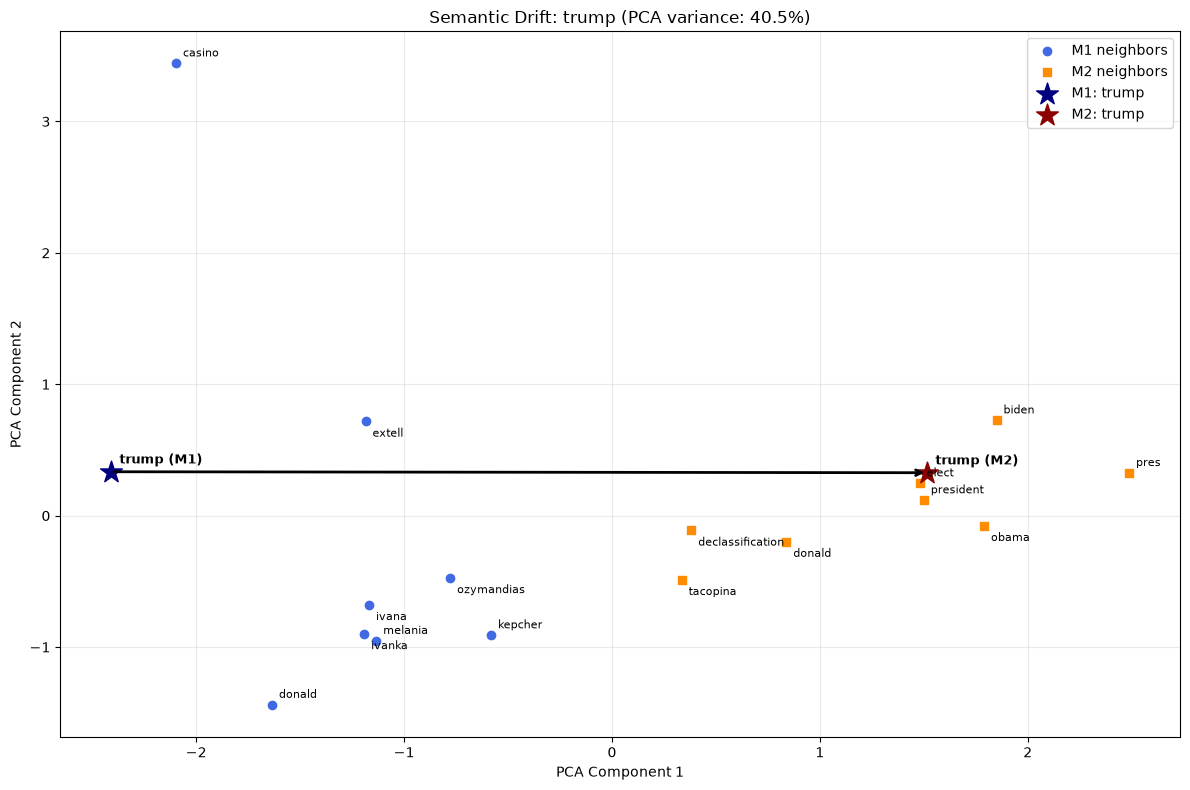

trump: 18 vectors; PCA variance retained = 40.5%


In [59]:
# 12. Trump: business/family to politics
plot_semantic_drift("trump")

Existing PNG kept: C:\Projects\IR\data\part2_results\plots\distancing_drift_plot.png


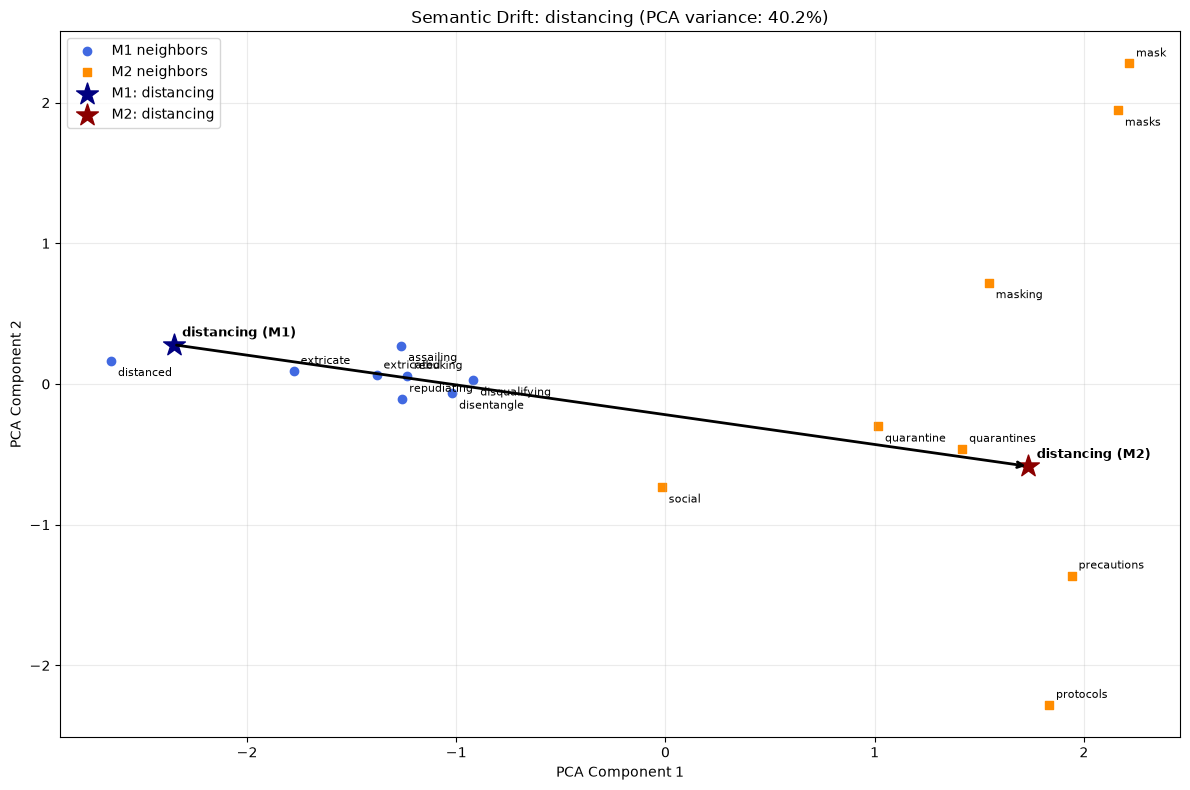

distancing: 18 vectors; PCA variance retained = 40.2%


In [60]:
# 13. Distancing: separation to public-health measures
plot_semantic_drift("distancing")

## 2.8: Emerging words and temporal analogues

**Emerging words:** We find words present in fresh M3 but absent from M1, ranked by their frequency in M3. Being absent from M1's vocabulary does **not** prove that a word was invented later.

**Temporal analogues:** For each newer query, we search **M1's vocabulary** for its five nearest words using either the continued M2 vector or the aligned M3 vector. These are related older words, not guaranteed synonyms or exact historical equivalents.

In [61]:
# 14. Twenty most frequent words in M3 but not M1
with open(RESULTS / "temporal_analogies.json", encoding="utf-8") as f:
    analogy_results = json.load(f)

emerging_df = pd.DataFrame(analogy_results["emerging_words"]["words"])
emerging_df = emerging_df.rename(columns={
    "rank": "Rank", "word": "Word", "m3_count": "M3 frequency"
})
display(emerging_df)

print("Total M3 words absent from M1:", analogy_results["emerging_words"]["available_count"])

,Rank,Word,M3 frequency
0,1,coronavirus,17826
1,2,covid,7565
2,3,tiktok,2085
3,4,2023,1717
4,5,brexit,1596
5,6,kyiv,1579
6,7,wordle,1350
7,8,omicron,1195
8,9,macron,1162
9,10,zelensky,1079


Total M3 words absent from M1: 4966


In [62]:
# 15. Ten query words and both sets of five M1 analogues (with scores)
rows = []
for query in analogy_results["queries"]:
    def neighbor_lines(key):
        return "<br>".join(
            f"{html.escape(n['word'])} ({n['cosine_similarity']:.3f})"
            for n in query[key]["neighbors"]
        )

    rows.append({
        "Query": html.escape(query["word"]),
        "M1 closest to continued M2[word]": neighbor_lines("m1_from_m2"),
        "M1 closest to aligned M3[word]": neighbor_lines("m1_from_m3_aligned"),
    })

display(HTML(pd.DataFrame(rows).to_html(index=False, escape=False)))

Query,M1 closest to continued M2[word],M1 closest to aligned M3[word]
covid,flu (0.585)vaccine (0.559)swine (0.551)hiv (0.542)ebola (0.523),flu (0.557)vaccine (0.523)swine (0.513)influenza (0.493)hiv (0.490)
zoom,facetime (0.448)gameplay (0.426)animatedly (0.415)conferencing (0.415)quora (0.413),facetime (0.427)keypad (0.412)untethered (0.412)pda (0.412)doodling (0.411)
trump,bush (0.648)obama (0.605)pres (0.544)mccain (0.512)romney (0.511),obama (0.555)bush (0.524)preemptive (0.512)cyberwar (0.498)obstructionism (0.488)
biden,obama (0.695)bush (0.601)president (0.533)romney (0.513)cafta (0.509),obama (0.625)bush (0.594)yoweri (0.470)administration (0.468)drawdown (0.466)
tiktok,youtube (0.608)facebook (0.580)myspace (0.524)twitter (0.507)snapchat (0.495),youtube (0.583)facebook (0.539)myspace (0.495)twitter (0.480)scrabulous (0.475)
instagram,youtube (0.595)twitter (0.589)facebook (0.533)influencers (0.522)thecaucus (0.513),youtube (0.578)twitter (0.570)facebook (0.555)tumblr (0.525)vimeo (0.514)
netflix,syfy (0.537)hbo (0.500)quarterlife (0.478)portlandia (0.475)flashforward (0.474),syfy (0.525)hbo (0.504)portlandia (0.488)flashforward (0.468)serials (0.468)
isis,qaeda (0.635)militants (0.609)mesopotamia (0.602)sunna (0.597)insurgents (0.579),insurgents (0.575)taliban (0.571)militants (0.567)qaeda (0.566)extremist (0.531)
pandemic,recession (0.554)downturn (0.535)decelerating (0.488)joblessness (0.479)hurricane (0.449),downturn (0.506)recession (0.486)hurricane (0.450)katrina (0.446)decelerating (0.432)
brexit,britain (0.484)eu (0.470)austerity (0.454)lse (0.447)tories (0.443),austerity (0.491)eu (0.447)bulgarians (0.440)tories (0.439)drachma (0.438)


## Key observations

- **`zoom`:** M1 is associated with cameras, while M2 is associated with video calls.
- **`ai`:** M1 is associated with names and art, while M2 is associated with artificial intelligence.
- **`distancing`:** M2 strongly reflects public-health vocabulary.
- **`mountain`, `wine`, and `baseball`:** Their general topics remain recognizable across periods.
- **`tiktok` and `covid`:** Their temporal analogues include older social platforms and disease-related terms.

These examples describe **patterns in the news corpora**, not proof that every use of a word changed meaning. The full methodology and results belong in the final report.